# Restaurant payments and visitor arrivals in Macao

Class D – Team 01. CISC7204, 2026/2027 Semester 1.

**Question.** Between January 2025 and September 2026, how were monthly overnight and same-day visitor arrivals associated with the electronic payment transaction value of restaurants and similar establishments in Macao?

The window is 21 months. Both series were downloaded on 4 November 2026. October 2026 payments were not published yet. We use "associated with" on purpose. Twenty-one months can show co-movement. They cannot show cause.

This notebook builds the monthly table from the files in `data/`, draws Figures 1–6, and fits the checks listed in the proposal. Run the cells from the top.


## 1. Setup

The notebook expects to live in `notebooks/`, with `data/` one level up. It writes `data/merged_monthly.csv` and the PNG files in `visuals/`.


In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import Image, display
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

HERE = Path.cwd()
if (HERE / "data" / "payment_levels.csv").exists():
    ROOT = HERE
elif (HERE.parent / "data" / "payment_levels.csv").exists():
    ROOT = HERE.parent
else:
    raise FileNotFoundError("Could not find data/payment_levels.csv next to this notebook.")

DATA = ROOT / "data"
VIS = ROOT / "visuals"
VIS.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

NAVY, BLUE, AMBER, GREEN, INK = "#1F4E79", "#0072B2", "#E69F00", "#009E73", "#222222"
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.edgecolor": "#444444",
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "text.color": INK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#E6E6E6",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})
print("Reading data from", DATA)


Reading data from /Users/chanchengi/Desktop/7204/Semester Project - Team (6 Pax) /deliverables/cisc7204-Class_D-Team_01-FinalProjectArchive/data


## 2. Why the Excel files are not the time series

The September 2026 payment workbook reports percentage changes for restaurants. It does not report the month's amount in patacas. The visitor workbook is a large cross-section for recent months, not a 21-month series of same-day and overnight counts. Both files stay in `data/` so that this claim can be checked.


In [2]:
pay_xl = pd.read_excel(DATA / "pay_m09.xlsx", header=None)
# Row 5 of the September 2026 sheet is restaurants. Columns are cumulative, year-on-year and month-on-month percent changes.
restaurant = pay_xl.iloc[5, 0].split("\n")[-1]
changes = pay_xl.iloc[5, 1:4].tolist()
print(restaurant)
print("cumulative / year-on-year / month-on-month, percent:", changes)

vis_xl = pd.ExcelFile(DATA / "vis_m09.xlsx")
print("visitor workbook sheets:", len(vis_xl.sheet_names))
print("first sheet title:", pd.read_excel(vis_xl, vis_xl.sheet_names[0], header=None).iloc[0, 0])


Restaurant & Similar Establishment
cumulative / year-on-year / month-on-month, percent: [2.2, 5.4, -11]
visitor workbook sheets: 45
first sheet title: 1. 按證件簽發地統計之入境旅客


## 3. Payment levels, typed from the 21 releases

`payment_levels.csv` holds the monthly restaurant total in MOP billion. January 2025 is not the figure in the first January release (MOP1.1 billion). The February 2025 release calls MOP1.3 billion the revised January figure, and that is the value we keep. The cell below finds that sentence.


In [3]:
levels = pd.read_csv(DATA / "payment_levels.csv")
assert list(levels.payment_billion.round(2))[0] == 1.30
assert len(levels) == 21

pay_news = json.loads((DATA / "pay_news.json").read_text())
feb = next(r for r in pay_news if str(r["y"]) == "2025" and int(r["m"]) == 2)
text = feb["t"].replace("&nbsp;", " ").replace("&amp;", "&")
start = text.find("Compared with the revised figure")
print(text[start:start + 110].strip())
levels[["year", "month", "payment_billion"]]


Compared with the revised figure in January (MOP1.3 billion), the transaction value receded by 14.1% in Februa


,year,month,payment_billion
0,2025,1,1.300
1,2025,2,1.120
2,2025,3,1.100
3,2025,4,1.050
4,2025,5,1.150
5,2025,6,1.060
6,2025,7,1.120
7,2025,8,1.200
8,2025,9,1.040
9,2025,10,1.160


## 4. Visitors from the same month's release

For each release we ignore the year-to-date paragraph and keep the sentence for that month. A published visitor total is kept only when it equals same-day plus overnight, within 5 persons. Otherwise the total is the sum. We do not fill a missing month. A missing month would be dropped and named.


In [4]:
MONTHS = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]

def as_int(text):
    return int(text.replace(",", ""))

def parse_visitors(rows):
    records = []
    for row in rows:
        year, month = int(row["y"]), int(row["m"])
        name = MONTHS[month - 1]
        start = row["t"].find(f"{name} {year}")
        if start < 0:
            start = row["t"].find(name)
        chunk = row["t"][start:start + 420]
        same = re.search(r"[Ss]ame-day visitors \(([\d,]+)\)", chunk)
        over = re.search(r"[Oo]vernight visitors \(([\d,]+)\)", chunk)
        total = re.search(r"to (\d{1,3}(?:,\d{3})+)", chunk)
        if not same or not over:
            raise ValueError(f"missing visitor counts for {year}-{month:02d}")
        same_n, over_n = as_int(same.group(1)), as_int(over.group(1))
        published = None
        if total:
            candidate = as_int(total.group(1))
            if abs(candidate - (same_n + over_n)) <= 5:
                published = candidate
        records.append({
            "year": year,
            "month": month,
            "total": published if published is not None else same_n + over_n,
            "same_day": same_n,
            "overnight": over_n,
            "total_published": published is not None,
        })
    return pd.DataFrame(records)

raw_news = json.loads((DATA / "vis_news.json").read_text())
visitors = parse_visitors(raw_news)
missing = []
for rec, src in zip(visitors.to_dict("records"), raw_news):
    if f"{rec['same_day'] + rec['overnight']:,}" not in src["t"]:
        missing.append(f"{rec['year']}-{rec['month']:02d}")
if missing:
    raise ValueError("same-day + overnight is not the total printed in " + ", ".join(missing))
print(len(visitors), "months. The total in the table is same-day plus overnight.")
print("That sum is printed in the release for every month.")
print(int(visitors.total_published.sum()), "months also had a matching total in the first sentence we checked;")
print("in the other months that first number was a different statistic, so it was not used.")
visitors.head(3)


21 months. The total in the table is same-day plus overnight.
That sum is printed in the release for every month.
6 months also had a matching total in the first sentence we checked;
in the other months that first number was a different statistic, so it was not used.


,year,month,total,same_day,overnight,total_published
0,2026,9,3216535,1933257,1283278,True
1,2026,8,4478073,2853011,1625062,False
2,2026,7,3542218,2107744,1434474,False


## 5. One row per month

Payment and visitors are matched on year and month. An unmatched month stops the notebook. Payment is then stored in MOP million, and visitor counts in thousands, so the later slope means MOP million per extra thousand visitors. Indexes use January 2025 as 100. Year-on-year changes exist only for the nine months of 2026.


In [5]:
pay = levels.rename(columns={"year": "year", "month": "month"})[["year", "month", "payment_billion"]]
df = pay.merge(visitors, on=["year", "month"], how="outer", indicator=True)
if (df["_merge"] != "both").any() or df["payment_billion"].isna().any():
    raise ValueError("payment and visitor months do not match")
df = df.drop(columns="_merge")
df["date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))
df = df.sort_values("date").reset_index(drop=True)

gap_months = df.date.diff().dt.days.dropna()
if (gap_months > 32).any():
    raise ValueError("the months are not consecutive")
if ((df.same_day + df.overnight - df.total).abs() > 5).any():
    raise ValueError("same-day + overnight does not match the total used")

df["payment_mop_million"] = df.payment_billion * 1000
df["overnight_thousands"] = df.overnight / 1000
df["same_day_thousands"] = df.same_day / 1000
df["total_thousands"] = df.total / 1000
df["overnight_share"] = df.overnight / df.total * 100
base = df.iloc[0]
df["payment_index"] = df.payment_mop_million / base.payment_mop_million * 100
df["overnight_index"] = df.overnight / base.overnight * 100
df["same_day_index"] = df.same_day / base.same_day * 100
df["payment_yoy"] = df.payment_mop_million.pct_change(12) * 100
df["overnight_yoy"] = df.overnight.pct_change(12) * 100
df["same_day_yoy"] = df.same_day.pct_change(12) * 100

keep = ["date", "year", "month", "payment_billion", "payment_mop_million",
        "total", "same_day", "overnight", "total_published",
        "overnight_thousands", "same_day_thousands", "total_thousands", "overnight_share",
        "payment_index", "overnight_index", "same_day_index",
        "payment_yoy", "overnight_yoy", "same_day_yoy"]
df[keep].to_csv(DATA / "merged_monthly.csv", index=False)
print(f"{len(df)} months, {df.date.min():%B %Y} to {df.date.max():%B %Y}")
df[["date", "payment_billion", "same_day", "overnight", "total", "total_published"]]


21 months, January 2025 to September 2026


,date,payment_billion,same_day,overnight,total,total_published
0,2025-01-01,1.300,2155279,1491282,3646561,False
1,2025-02-01,1.120,1887826,1259358,3147184,False
2,2025-03-01,1.100,1780279,1288641,3068920,False
3,2025-04-01,1.050,1755592,1337199,3092791,False
4,2025-05-01,1.150,1992296,1379785,3372081,False
5,2025-06-01,1.060,1611641,1279362,2891003,True
6,2025-07-01,1.120,1980732,1477634,3458366,False
7,2025-08-01,1.200,2553316,1665718,4219034,False
8,2025-09-01,1.040,1561568,1213562,2775130,True
9,2025-10-01,1.160,2103520,1368957,3472477,False


## 6. Figure 1. The payment series on its own

Across these 21 months the low is September 2025, MOP1.04 billion, and the high is the revised January 2025 figure, MOP1.30 billion. September 2026 is MOP1.10 billion. February 2026, which includes Lunar New Year, is MOP1.28 billion.

The vertical axis does not start at zero. The series only moves between about 1,040 and 1,300 million, and a zero baseline would flatten the month-to-month movement this chart is for. The axis title says the unit, so the level is still readable. The chart does not say which visitor group the payments move with.


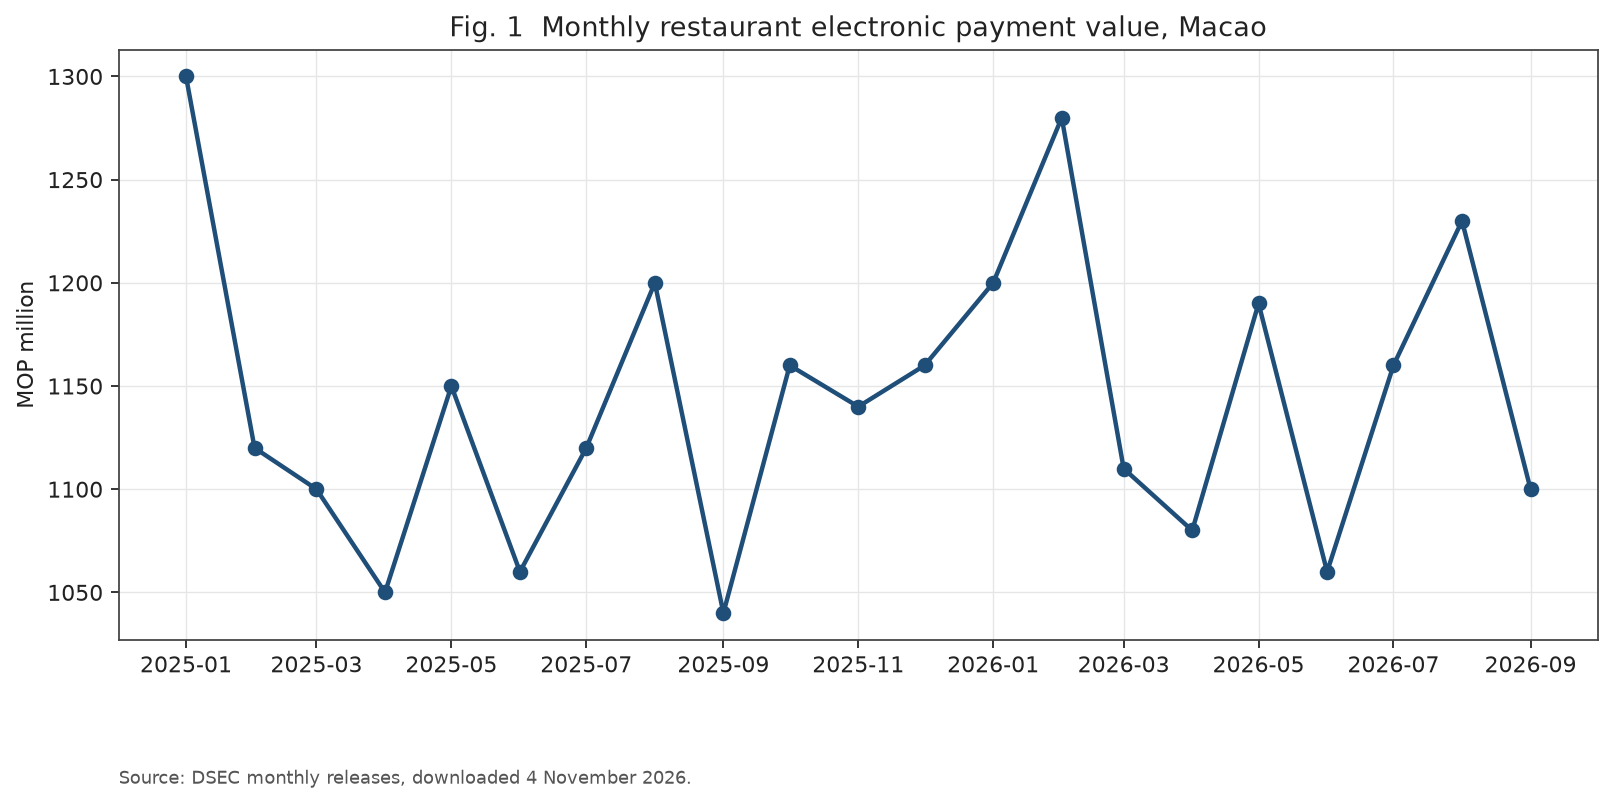

In [6]:
def source(ax, text="Source: DSEC monthly releases, downloaded 4 November 2026."):
    ax.annotate(text, xy=(0, -0.22), xycoords="axes fraction",
                ha="left", va="top", fontsize=8, color="#555555")

def save(fig, name):
    fig.tight_layout()
    path = VIS / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

fig, ax = plt.subplots(figsize=(10.2, 5.2))
ax.plot(df.date, df.payment_mop_million, color=NAVY, marker="o", linewidth=2)
ax.set_title("Fig. 1  Monthly restaurant electronic payment value, Macao")
ax.set_ylabel("MOP million")
ax.set_xlabel("")
source(ax)
save(fig, "fig1_payment.png")


**Reading Figure 1.** The title states the series and the place. The source line gives the download date. There is one line and no second encoding of the same numbers. That is enough decoration.

It is truthful in the narrow sense we can check: January 2025 is the revised 1.30, not the first published 1.1, and the chart does not call the series revenue. It is not a picture of all restaurant takings. Cash is missing, and residents are included.

It is functional for the first look. A reader can see that the series stays in a fairly narrow band and that February 2026 is a high month. It is not functional for the research question yet, because the visitors are not on it.

Calling it beautiful would oversell a line chart. It is plain, which is what we wanted. The useful point is the narrow band. Visitor counts swing more than payments do, and Figure 3 is there so that comparison is visible.


## 7. Figure 2. The two visitor groups

In September 2026 there were 1,933,257 same-day visitors and 1,283,278 overnight visitors. The overnight share stays near 40% and falls to 35.9% in February 2026, when same-day arrivals jump. Same-day visitors are the larger group in every month of this window.


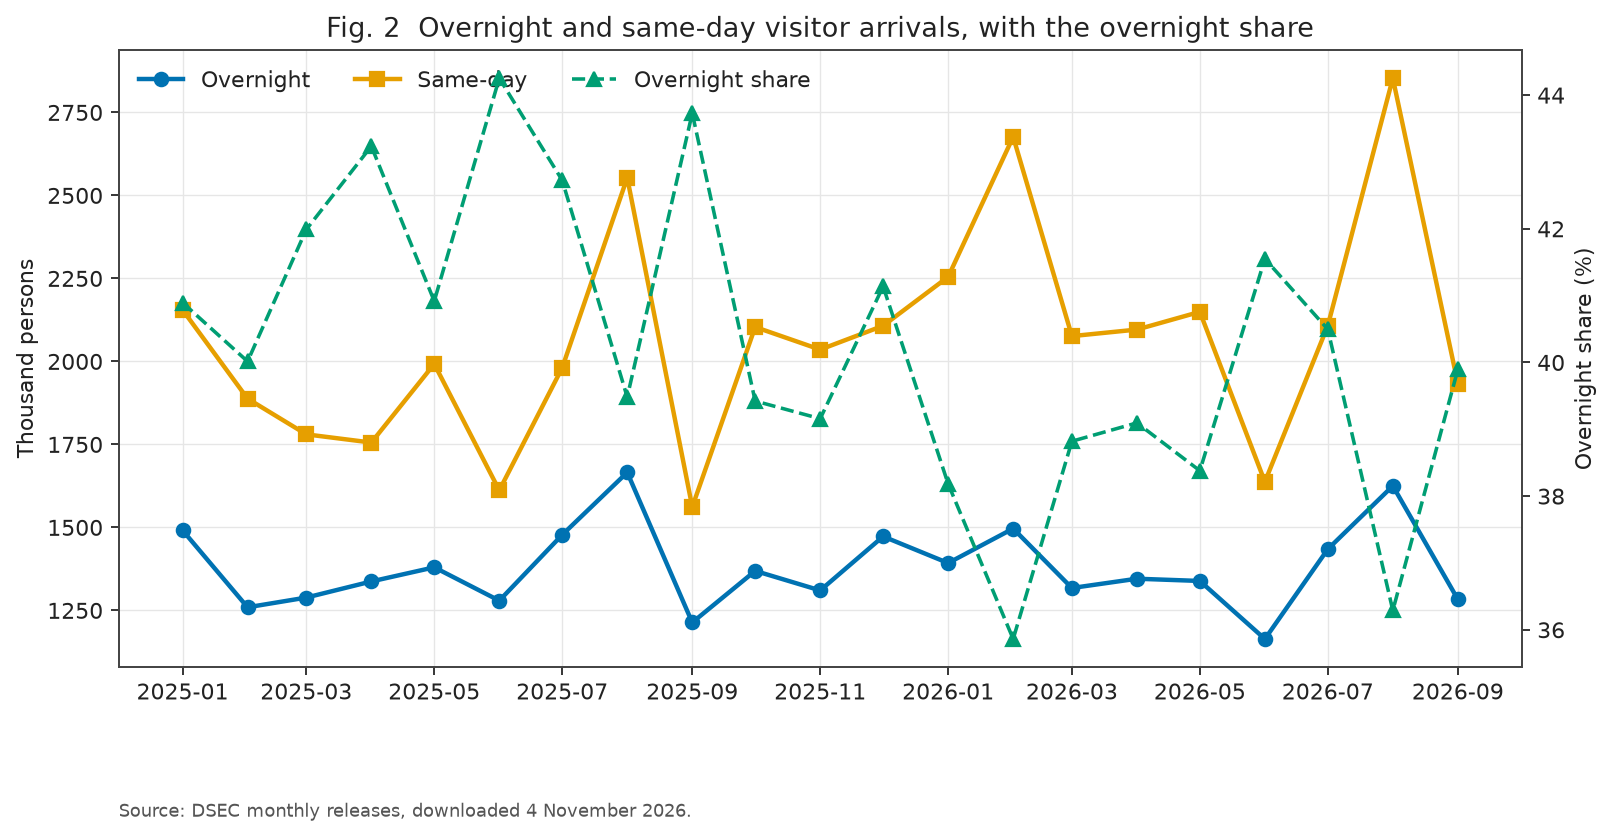

September 2026 same-day 1933257 overnight 1283278
February 2026 overnight share 35.9


In [7]:
fig, ax = plt.subplots(figsize=(10.2, 5.4))
ax.plot(df.date, df.overnight_thousands, color=BLUE, marker="o", label="Overnight", linewidth=2)
ax.plot(df.date, df.same_day_thousands, color=AMBER, marker="s", label="Same-day", linewidth=2)
ax.set_ylabel("Thousand persons")
ax2 = ax.twinx()
ax2.plot(df.date, df.overnight_share, color=GREEN, linestyle="--", marker="^",
         label="Overnight share", linewidth=1.6)
ax2.set_ylabel("Overnight share (%)")
ax2.grid(False)
ax.set_title("Fig. 2  Overnight and same-day visitor arrivals, with the overnight share")
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, frameon=False, ncol=3, loc="upper left")
source(ax)
save(fig, "fig2_arrivals.png")
print("September 2026 same-day", int(df.iloc[-1].same_day), "overnight", int(df.iloc[-1].overnight))
print("February 2026 overnight share", round(float(df.loc[df.date == "2026-02-01", "overnight_share"].iloc[0]), 1))


**Reading Figure 2.** Two solid lines use the left axis, in thousand persons. The share is a dashed line on its own axis, because a percentage is not a count. The colours stay the same in the later charts.

The counts are the ones printed in the releases, after the year-to-date sentence was set aside. The chart is truthful about the split DSEC publishes. It does not show how long anyone stayed, or what they spent.

It does the job it was drawn for: same-day is the larger flow, and the share dips when same-day arrivals jump at Lunar New Year. It still cannot say whether that jump shows up in restaurant payments. The two axes are a compromise. A reader has to notice which line belongs to which scale. The legend is there for that reason.


## 8. Figure 3. A common base

January 2025 is 100 for all three series. In August 2026 the same-day index is 132 and the payment index is 95. The chart compares relative movement. It does not measure spending per visitor.


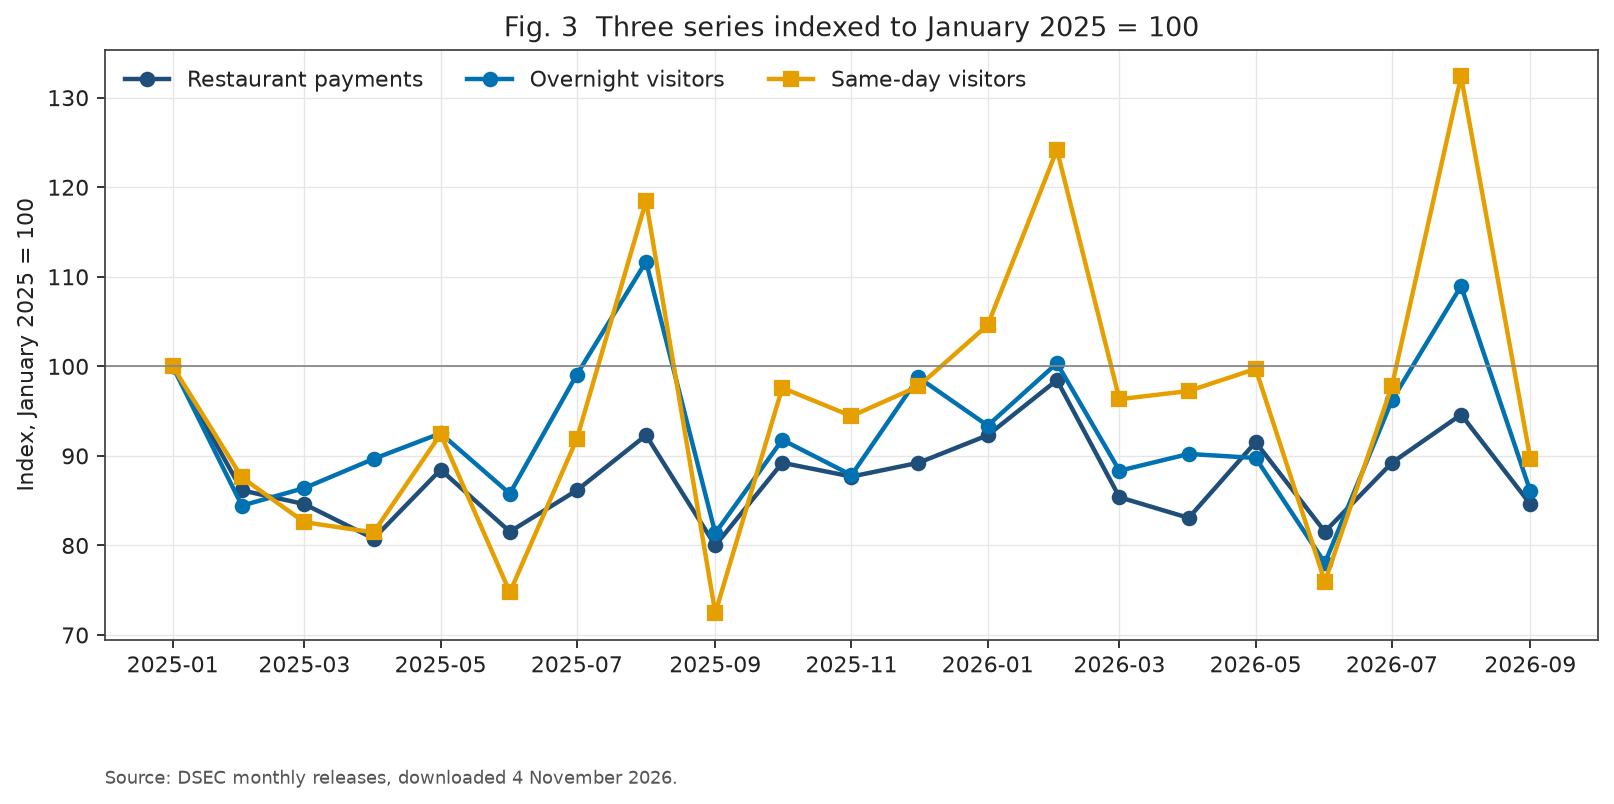

August 2026 payment index 95 same-day index 132


In [8]:
fig, ax = plt.subplots(figsize=(10.2, 5.2))
ax.plot(df.date, df.payment_index, color=NAVY, marker="o", label="Restaurant payments", linewidth=2)
ax.plot(df.date, df.overnight_index, color=BLUE, marker="o", label="Overnight visitors", linewidth=2)
ax.plot(df.date, df.same_day_index, color=AMBER, marker="s", label="Same-day visitors", linewidth=2)
ax.axhline(100, color="#888888", linewidth=0.8)
ax.set_title("Fig. 3  Three series indexed to January 2025 = 100")
ax.set_ylabel("Index, January 2025 = 100")
ax.legend(frameon=False, ncol=3)
source(ax)
save(fig, "fig3_index.png")
aug = df.loc[df.date == "2026-08-01", ["payment_index", "same_day_index"]].iloc[0]
print("August 2026 payment index", round(aug.payment_index), "same-day index", round(aug.same_day_index))


**Reading Figure 3.** Indexing is a design choice, and it needs the base in the title. Without that sentence, 132 could be misread as a count. With it, the chart shows that same-day arrivals moved further from their January 2025 level than payments did.

The chart is not evidence that restaurants failed to gain from the extra visitors. Payments include residents, exclude cash, and are already a value rather than a headcount. An index of 95 against an index of 132 says the two series did not move by the same proportion. That is all.


## 9. Figure 4. Year-on-year change, description only

There are nine year-on-year values, January to September 2026. That is too few for the correlation or the regression, so this chart is not used in either. In September 2026, payments are up 5.8%, overnight arrivals 5.7%, and same-day arrivals 23.8%. February 2026 is the large same-day increase, 41.8%, against a 14.3% rise in payments.


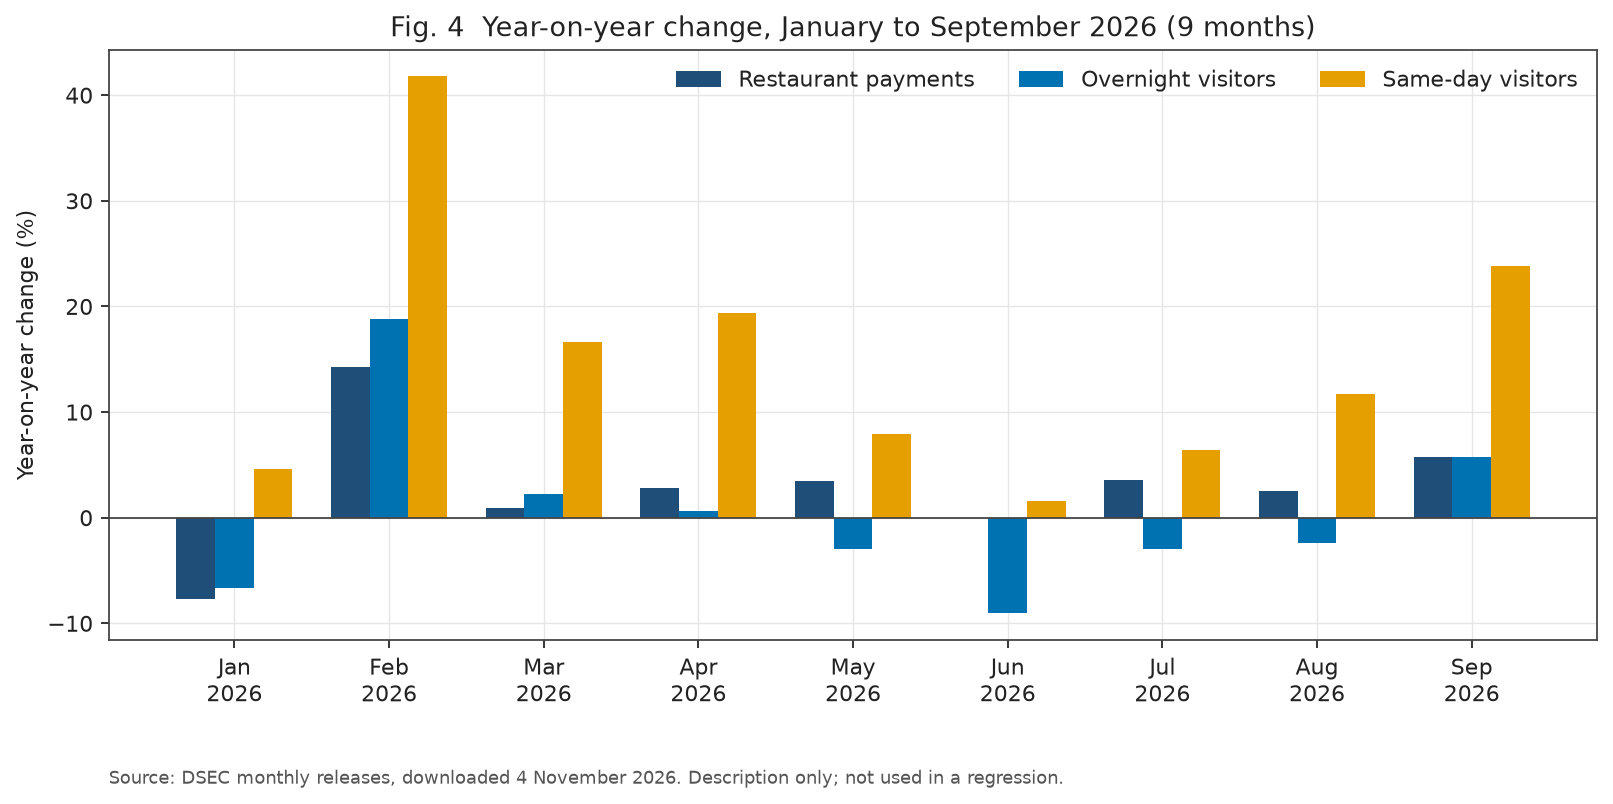

   date  payment_yoy  overnight_yoy  same_day_yoy
2026-02       14.300         18.800        41.800
2026-09        5.800          5.700        23.800


In [9]:
yoy = df.dropna(subset=["payment_yoy"]).copy()
fig, ax = plt.subplots(figsize=(10.2, 5.2))
x = np.arange(len(yoy))
width = 0.25
ax.bar(x - width, yoy.payment_yoy, width, color=NAVY, label="Restaurant payments")
ax.bar(x, yoy.overnight_yoy, width, color=BLUE, label="Overnight visitors")
ax.bar(x + width, yoy.same_day_yoy, width, color=AMBER, label="Same-day visitors")
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(yoy.date.dt.strftime("%b\n%Y"))
ax.set_ylabel("Year-on-year change (%)")
ax.set_title("Fig. 4  Year-on-year change, January to September 2026 (9 months)")
ax.legend(frameon=False, ncol=3)
source(ax, "Source: DSEC monthly releases, downloaded 4 November 2026. Description only; not used in a regression.")
save(fig, "fig4_yoy.png")
show = yoy.loc[yoy.date.dt.strftime("%Y-%m-%d").isin(["2026-02-01", "2026-09-01"]),
               ["date", "payment_yoy", "overnight_yoy", "same_day_yoy"]].copy()
show["date"] = show.date.dt.strftime("%Y-%m")
print(show.round(1).to_string(index=False))


**Reading Figure 4.** Grouped bars put the three growth rates for one month next to each other. The zero line is drawn because a year-on-year change can be negative, and June 2026 overnight arrivals are. Nine groups are few enough to label by month.

The chart is easy to over-read. A taller same-day bar does not mean same-day visitors caused the payment change. It shows that, in several months of 2026, same-day arrivals grew faster than the payment total. We stop there. These nine numbers do not enter the model.


## 10. Correlation, then Figure 5

Levels can look tightly related because the series share holiday peaks. Month-to-month changes, 20 values, take most of that shared trend out. We give the change-based correlations more weight, as we said we would before fitting anything. Figure 5 is the same comparison as a scatter, with each month labelled.


Pearson, levels
                     payment_mop_million  overnight_thousands  same_day_thousands  total_thousands
payment_mop_million                1.000                0.730               0.815            0.816
overnight_thousands                0.730                1.000               0.848            0.918
same_day_thousands                 0.815                0.848               1.000            0.988
total_thousands                    0.816                0.918               0.988            1.000

Pearson, month-to-month changes
                     payment_mop_million  overnight_thousands  same_day_thousands  total_thousands
payment_mop_million                1.000                0.833               0.879            0.880
overnight_thousands                0.833                1.000               0.925            0.961
same_day_thousands                 0.879                0.925               1.000            0.994
total_thousands                    0.880                0.96

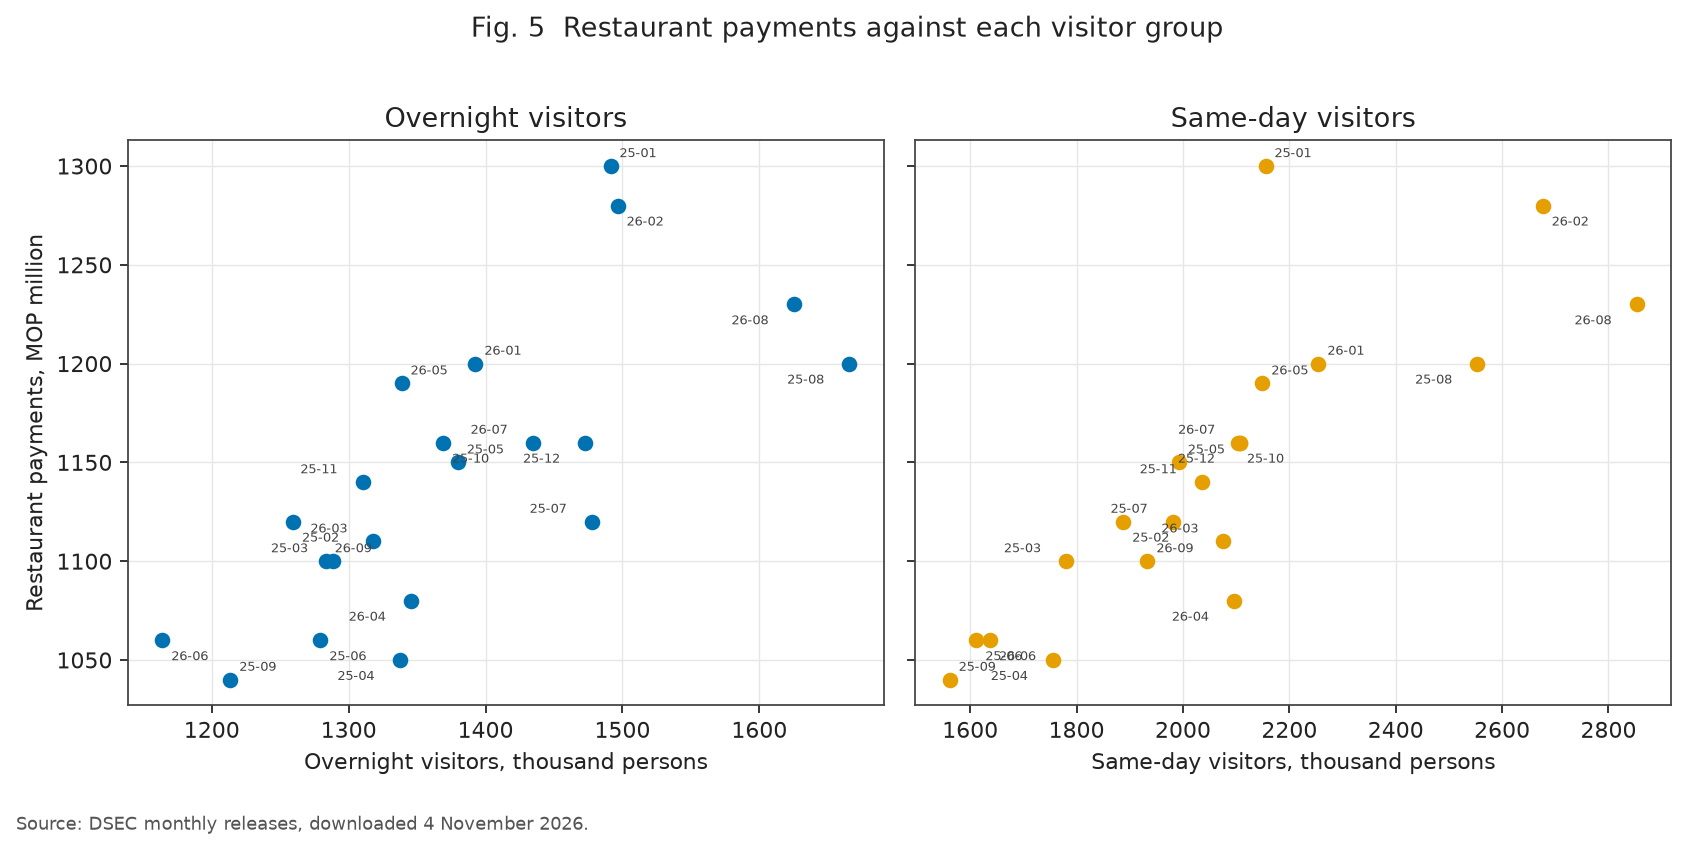

In [10]:
cols = ["payment_mop_million", "overnight_thousands", "same_day_thousands", "total_thousands"]
print("Pearson, levels")
print(df[cols].corr().round(3))
print("\nPearson, month-to-month changes")
print(df[cols].diff().corr().round(3))

print("\nSpearman, levels / changes")
for col in ["overnight_thousands", "same_day_thousands", "total_thousands"]:
    level = stats.spearmanr(df.payment_mop_million, df[col]).statistic
    changed = df[["payment_mop_million", col]].diff().dropna()
    diff = stats.spearmanr(changed.payment_mop_million, changed[col]).statistic
    print(f"  {col}: {level:.3f} / {diff:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), sharey=True)
pairs = [(axes[0], "overnight_thousands", BLUE, "Overnight visitors"),
         (axes[1], "same_day_thousands", AMBER, "Same-day visitors")]
for ax, col, color, label in pairs:
    ax.scatter(df[col], df.payment_mop_million, color=color, s=36, zorder=3)
    offsets = [(4, 4), (4, -9), (-28, 4), (-28, -9)]
    for i, (_, row) in enumerate(df.iterrows()):
        ax.annotate(row.date.strftime("%y-%m"),
                    (row[col], row.payment_mop_million),
                    textcoords="offset points", xytext=offsets[i % 4],
                    fontsize=6, color="#444444")
    ax.set_xlabel(f"{label}, thousand persons")
    ax.set_title(label)
axes[0].set_ylabel("Restaurant payments, MOP million")
fig.suptitle("Fig. 5  Restaurant payments against each visitor group", y=1.02)
fig.text(0.01, -0.04, "Source: DSEC monthly releases, downloaded 4 November 2026.", fontsize=8, color="#555555")
save(fig, "fig5_scatter.png")


**Reading Figure 5.** The two panels share the payment axis, so a month that sits high on the left can be compared with the same month on the right. Labels are small because 21 points with full dates would cover the line. The year-month stamp is enough to find January 2025 and February 2026.

Same-day arrivals line up a little more closely with payments than overnight arrivals do: Pearson 0.81 against 0.73 in levels, and 0.88 against 0.83 in month-to-month changes. The two visitor groups also move together, 0.85 in levels and 0.92 in changes. The scatter therefore does not separate their contributions. That is a limit of the chart, not a detail to talk past.


## 11. The two-predictor model, and Figure 6

Payment is in MOP million. Arrivals are in thousands. Each slope is the change in monthly payment value associated with one thousand more visitors of that type, holding the other type constant. Total arrivals are not in this model, because total = same-day + overnight.

A slope of 0.15 is about MOP150 per extra same-day visitor. A slope of 0.08 is about MOP80 per extra overnight visitor. The intervals below use a t distribution with 18 residual degrees of freedom. The November presentation slide rounded the overnight interval with a normal approximation. This cell is the one the report follows.


                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 720.7026    120.081      6.002      0.000     468.423     972.982
overnight_thousands     0.0789      0.145      0.542      0.594      -0.227       0.385
same_day_thousands      0.1522      0.056      2.728      0.014       0.035       0.269
R-squared 0.669 Adj. 0.632
VIF overnight / same-day [3.55, 3.55]
Durbin-Watson 1.35
Largest Cook's distance 0.53 in 2025-01-01
January 2025 residual, MOP million 133.6 share of SSE 0.521


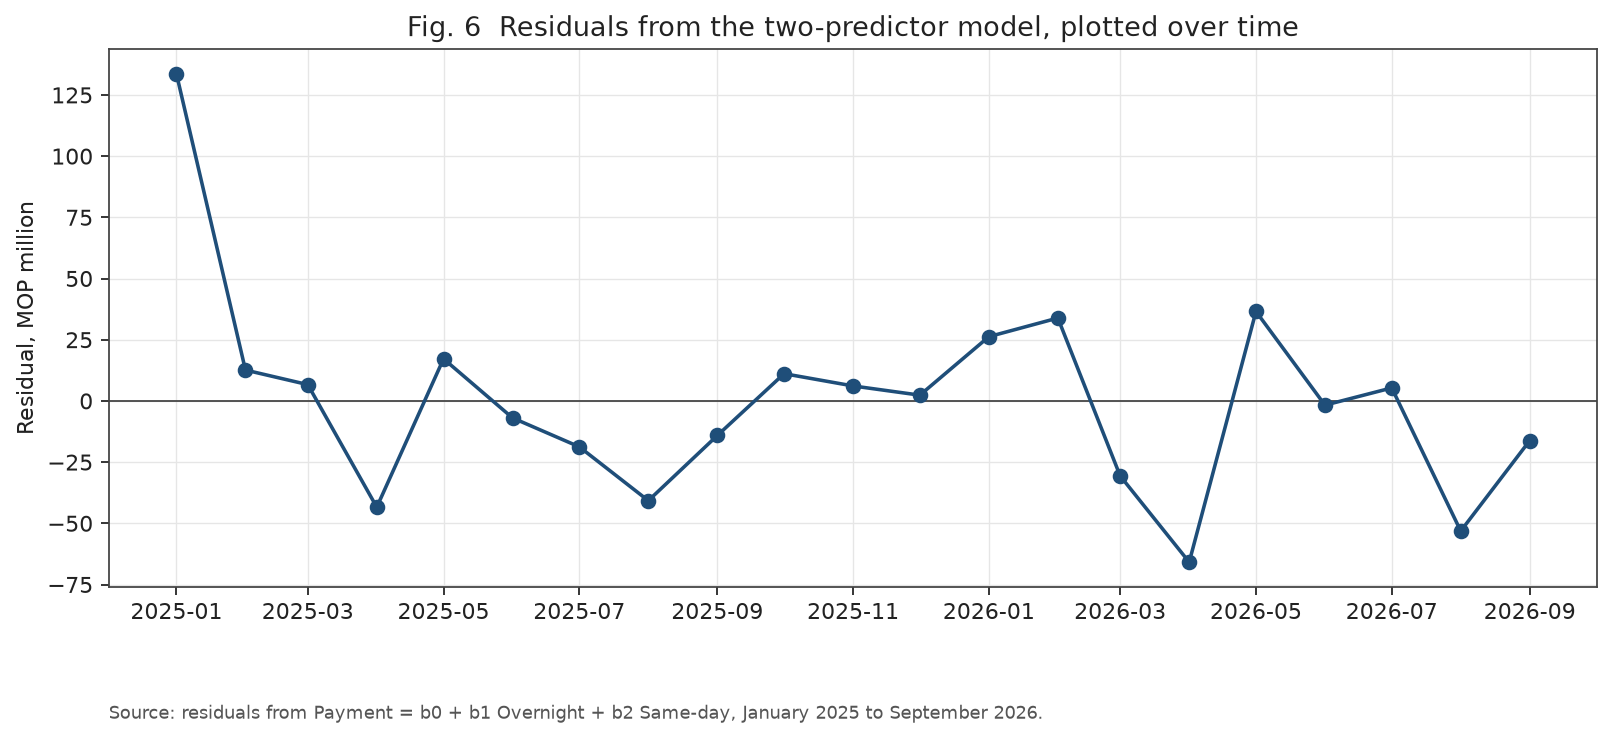

In [11]:
y = df.payment_mop_million
X = sm.add_constant(df[["overnight_thousands", "same_day_thousands"]])
model = sm.OLS(y, X).fit()
vif = [variance_inflation_factor(np.asarray(X, dtype=float), i) for i in (1, 2)]
influence = model.get_influence()
cooks = influence.cooks_distance[0]
sse = float(np.sum(model.resid ** 2))
jan_share = float(model.resid.iloc[0] ** 2 / sse)

print(model.summary().tables[1])
print("R-squared", round(model.rsquared, 3), "Adj.", round(model.rsquared_adj, 3))
print("VIF overnight / same-day", [round(float(v), 2) for v in vif])
print("Durbin-Watson", round(durbin_watson(model.resid), 2))
print("Largest Cook's distance", round(float(cooks.max()), 2), "in", df.date.iloc[int(np.argmax(cooks))].date())
print("January 2025 residual, MOP million", round(float(model.resid.iloc[0]), 1), "share of SSE", round(jan_share, 3))

fig, ax = plt.subplots(figsize=(10.2, 4.8))
ax.axhline(0, color="#444444", linewidth=0.8)
ax.plot(df.date, model.resid, color=NAVY, marker="o", linewidth=1.6)
ax.set_title("Fig. 6  Residuals from the two-predictor model, plotted over time")
ax.set_ylabel("Residual, MOP million")
source(ax, "Source: residuals from Payment = b0 + b1 Overnight + b2 Same-day, January 2025 to September 2026.")
save(fig, "fig6_residuals.png")


**Reading Figure 6.** A residual above zero means the month's payment was higher than the two slopes predicted. January 2025 is that point. It is also the revised payment month, and it accounts for about half of the squared error. The Durbin–Watson statistic is 1.35. With 21 observations we treat that only as a warning that some serial correlation is left, not as a formal test.

The same-day interval, about 0.04 to 0.27, stays positive. The overnight interval, about −0.23 to 0.38, includes zero and is wide. The variance inflation factor is 3.55. The separate overnight slope is not something we are willing to quote on its own.

The chart is honest about the misfit only if the reader knows the vertical scale is MOP million and the zero line is a perfect fit. It does not identify a cause for the January residual.


## 12. The checks we said we would report

Spearman correlations sit beside the Pearson ones above. The two single-predictor fits, the model with total arrivals and the overnight share, and a leave-one-month-out pass are below. Hotel occupancy is not here. The proposal allowed us to drop it, and we did. Occupancy moves with overnight arrivals, so it would not have held an outside factor constant.

If the overnight slope changes sign when one month is removed, we will not interpret it.


In [12]:
rows = []
for col, label in [("overnight_thousands", "Overnight only"), ("same_day_thousands", "Same-day only")]:
    fit = sm.OLS(y, sm.add_constant(df[col])).fit()
    lo, hi = fit.conf_int().loc[col]
    rows.append([label, round(fit.params[col], 3), round(lo, 3), round(hi, 3), round(fit.rsquared, 3)])

alt = sm.OLS(y, sm.add_constant(df[["total_thousands", "overnight_share"]])).fit()
for col, label in [("total_thousands", "Total arrivals, with the share in the model"),
                   ("overnight_share", "Overnight share, with total arrivals in the model")]:
    lo, hi = alt.conf_int().loc[col]
    rows.append([label, round(alt.params[col], 3), round(lo, 3), round(hi, 3), round(alt.rsquared, 3)])

checks = pd.DataFrame(rows, columns=["Specification", "Slope", "CI low", "CI high", "R-squared"])
display(checks)

loo_o, loo_s = [], []
for i in range(len(df)):
    sub = df.drop(df.index[i])
    fit = sm.OLS(sub.payment_mop_million, sm.add_constant(sub[["overnight_thousands", "same_day_thousands"]])).fit()
    loo_o.append(fit.params["overnight_thousands"])
    loo_s.append(fit.params["same_day_thousands"])
print("Leave-one-month-out, overnight slope: {:.3f} to {:.3f}".format(min(loo_o), max(loo_o)))
print("Leave-one-month-out, same-day slope: {:.3f} to {:.3f}".format(min(loo_s), max(loo_s)))
dropped = df.drop(index=0)
fit_drop = sm.OLS(dropped.payment_mop_million,
                  sm.add_constant(dropped[["overnight_thousands", "same_day_thousands"]])).fit()
print("Dropping January 2025, overnight slope", round(fit_drop.params["overnight_thousands"], 3),
      "same-day slope", round(fit_drop.params["same_day_thousands"], 3))


,Specification,Slope,CI low,CI high,R-squared
0,Overnight only,0.415,0.228,0.602,0.532
1,Same-day only,0.178,0.117,0.239,0.664
2,"Total arrivals, with the share in the model",0.117,0.046,0.188,0.673
3,"Overnight share, with total arrivals in the model",-4.048,-18.189,10.094,0.673


Leave-one-month-out, overnight slope: -0.062 to 0.167
Leave-one-month-out, same-day slope: 0.124 to 0.192
Dropping January 2025, overnight slope -0.062 same-day slope 0.192


## 13. What we take from the run

Same-day arrivals move with restaurant electronic payments in this sample, in the levels, in the month-to-month changes, and in the joint model. Overnight arrivals move with payments on their own, and then lose that separate slope once same-day arrivals are in the equation. Dropping January 2025 turns the overnight slope negative. We therefore describe the result as a same-day association, and we do not quote an overnight effect.

Nothing here is a spending-per-visitor figure, and nothing here is a cause. The payment series includes residents and excludes cash. Twenty-one months are one seasonal cycle.
